# DCF Valuation of Apple Inc. (AAPL)

A discounted cash flow (DCF) model built in Python, using financial data from Yahoo Finance.

**Result (as of November 2026):** base-case value of about **\$132 per share** vs. a market price of about **\$356**.
A sensitivity analysis shows the market price is only justified with a WACC near 6% and terminal growth of 3–3.5%.

**Steps:**
1. Data: income statement, cash flow statement, balance sheet
2. Free cash flow to the firm (FCFF)
3. 5-year forecast
4. Beta (own regression) and WACC
5. Terminal value
6. Enterprise value → value per share
7. Sensitivity analysis
8. Reverse DCF
9. Monte Carlo simulation

## Step 1: Setup and data
Imports the Python libraries and downloads Apple's annual financial statements (income statement,
cash flow statement, balance sheet) and company information from Yahoo Finance via the `yfinance` library.
The tables are transposed so that each row is a fiscal year, oldest first.

In [126]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy import stats
from scipy.optimize import brentq
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

ticker = yf.Ticker("AAPL")
income_t = ticker.income_stmt.T.sort_index()
cf_t = ticker.cashflow.T.sort_index()
bal_t = ticker.balance_sheet.T.sort_index()
info = ticker.info

## Step 2: Free cash flow (FCFF)
Free cash flow to the firm is the cash the business generates after taxes and the investments needed
to keep it running, i.e. the cash available to all investors (shareholders and lenders).

FCFF = EBIT × (1 − tax rate) + D&A − CapEx − change in net working capital

Note on signs: in Yahoo's data, CapEx is stored as a negative number and the change in working capital
is stored from the cash point of view, so both are **added** in the code.

In [127]:
print(f"Average effective tax rate: {tax_rate:.1%}")

fcff_table = pd.DataFrame({
    "EBIT": ebit,
    "Taxes on EBIT": -ebit * tax_rate,
    "D&A": da,
    "CapEx": capex,
    "Change NWC": change_nwc,
    "FCFF": fcff,
}).dropna() / 1e9

fcff_table["FCF margin %"] = fcff / revenue * 100
fcff_table["Net margin %"] = income_t["Net Income"] / revenue * 100
display(fcff_table.round(1))

Average effective tax rate: 17.9%


,EBIT,Taxes on EBIT,D&A,CapEx,Change NWC,FCFF,FCF margin %,Net margin %
2023-09-30,114.3,-20.4,11.5,-11.0,-6.6,87.9,22.9,25.3
2024-09-30,123.2,-22.0,11.4,-9.4,3.7,106.9,27.3,24.0
2025-09-30,133.0,-23.8,11.7,-12.7,-25.0,83.3,20.0,26.9
2026-09-30,158.1,-28.2,13.4,-9.0,-14.9,119.4,24.9,27.6


FCF is more volatile than net income (FCF margin 20–27% vs. net margin 24–28%), mainly because of
working capital timing, e.g. in FY2025 cash tied up in working capital pushed the FCF margin down to 20%.
This is why the forecast uses average or median ratios instead of a single year.

## Step 3: 5-year forecast
Revenue is forecast first; all other items are expressed as a percentage of revenue, based on their
historical values. This keeps every assumption visible and easy to change.

### 3a: History

In [128]:
ratios = pd.DataFrame({
    "EBIT margin": ebit / revenue,
    "D&A %": da / revenue,
    "CapEx %": capex / revenue,
    "NWC change %": change_nwc / revenue,
})

growth = revenue.pct_change() * 100
history = (ratios * 100).assign(**{"Revenue growth %": growth}).dropna()
display(history.round(1))
display((ratios.mean() * 100).round(1).rename("Average %"))

,EBIT margin,D&A %,CapEx %,NWC change %,Revenue growth %
2024-09-30,31.5,2.9,-2.4,0.9,2.0
2025-09-30,32.0,2.8,-3.1,-6.0,6.4
2026-09-30,33.0,2.8,-1.9,-3.1,15.1


EBIT margin     31.6
D&A %            2.9
CapEx %         -2.6
NWC change %    -2.5
Name: Average %, dtype: float64

### 3b: Assumptions
- **Revenue growth** 8% → 7% → 5% → 4% → 3%: the 15% growth in FY2026 is treated as a one-off;
  growth fades towards the long-run rate.
- **EBIT margin** 32.5%: between the 4-year average (31.6%) and the latest year (33%), reflecting the rising trend.
- **NWC change** = median of historical values, to reduce the impact of extreme years (conservative).
- **D&A and CapEx** = historical averages (both stable).

In [129]:
assumptions = {
    "growth": [0.08, 0.07, 0.05, 0.04, 0.03],   # 15% in 2026 seen as one-off; fade to 3%
    "ebit_margin": 0.325,                        # between average (31.6%) and latest (33%)
    "da_pct": ratios["D&A %"].mean(),
    "capex_pct": ratios["CapEx %"].mean(),
    "nwc_pct": ratios["NWC change %"].median(),  # median to reduce extremes
    "tax_rate": tax_rate,
}

### 3b: Forecast

In [130]:
rows = []
rev = revenue.iloc[-1]
for year, g_year in enumerate(assumptions["growth"], start=1):
    rev = rev * (1 + g_year)
    ebit_f = rev * assumptions["ebit_margin"]
    fcff_f = (ebit_f * (1 - assumptions["tax_rate"])
              + rev * assumptions["da_pct"]
              + rev * assumptions["capex_pct"]
              + rev * assumptions["nwc_pct"])
    rows.append({"year": year, "revenue": rev, "ebit": ebit_f, "fcff": fcff_f})

forecast = pd.DataFrame(rows).set_index("year")

forecast_table = forecast[["revenue", "ebit", "fcff"]] / 1e9
forecast_table.columns = ["Revenue (bn)", "EBIT (bn)", "FCFF (bn)"]
forecast_table["FCF margin %"] = forecast["fcff"] / forecast["revenue"] * 100
display(forecast_table.round(1))

,Revenue (bn),EBIT (bn),FCFF (bn),FCF margin %
year,,,,
1,517.1,168.1,127.3,24.6
2,553.3,179.8,136.2,24.6
3,581.0,188.8,143.0,24.6
4,604.2,196.4,148.8,24.6
5,622.4,202.3,153.2,24.6


Revenue grows from about 479 bn (FY2026) to about 622 bn in year 5. The forecast FCF margin (≈24.6%)
is close to recent history (24.9% in FY2026), so the forecast is consistent with Apple's past performance.

## Step 4: Calculating beta and WACC
### 4a: Beta (own regression)

In [131]:
prices = yf.download(["AAPL", "^GSPC"], period="5y", interval="1mo", auto_adjust=True, progress = False)["Close"]
prices = prices.iloc[:-1]                      # drop unfinished month
returns = prices.pct_change().dropna()
returns.columns = ["apple", "market"]

x = returns["market"]
y = returns["apple"]
x_mean, y_mean = x.mean(), y.mean()
beta_manual = ((x - x_mean) * (y - y_mean)).sum() / ((x - x_mean)**2).sum()
alpha_manual = y_mean - beta_manual * x_mean

result = stats.linregress(x, y)
print(f"Own beta: {beta_manual:.3f}  (scipy: {result.slope:.3f}, SE {result.stderr:.3f})")

Own beta: 1.085  (scipy: 1.085, SE 0.153)


### 4b: WACC

In [132]:
tnx = yf.Ticker("^TNX").history(period="5d")
risk_free = tnx["Close"].iloc[-1] / 100
equity_premium = 0.05
cost_equity = risk_free + beta_manual * equity_premium

E = info["marketCap"]
D = bal_t["Total Debt"].iloc[-1]
interest = income_t["Interest Expense"].dropna() if "Interest Expense" in income_t else pd.Series(dtype=float)
if len(interest) > 0:
    cost_debt = abs(interest.iloc[-1]) / D
else:
    cost_debt = risk_free + 0.01

wacc = (E/(E+D)) * cost_equity + (D/(E+D)) * cost_debt * (1 - tax_rate)

print(f"Risk-free: {risk_free:.2%}, cost of equity: {cost_equity:.2%}, cost of debt: {cost_debt:.2%}")
print(f"Weights: equity {E/(E+D):.1%}, debt {D/(E+D):.1%}")
print(f"WACC: {wacc:.2%}")

Risk-free: 4.85%, cost of equity: 10.27%, cost of debt: 4.91%
Weights: equity 98.5%, debt 1.5%
WACC: 10.18%


## Step 5: Terminal value
Cash flows after year 5 are valued with the Gordon growth formula, assuming 3% growth forever.

In [133]:
g = 0.03
N = len(forecast)

fcff_last = forecast["fcff"].iloc[-1]
tv = fcff_last * (1 + g) / (wacc - g)
pv_tv = tv / (1 + wacc) ** N

print(f"FCFF year 5: {fcff_last/1e9:.1f} bn")
print(f"Terminal value (year 5): {tv/1e9:.0f} bn")
print(f"PV of terminal value (today): {pv_tv/1e9:.0f} bn")


FCFF year 5: 153.2 bn
Terminal value (year 5): 2199 bn
PV of terminal value (today): 1354 bn


The terminal value makes up about 72% of the enterprise value. The DCF is most sensitive to the terminal
growth rate and the WACC, because the terminal value depends on the gap between them: raising g by one
percentage point (e.g. 3% → 4%) increases the PV of the terminal value by roughly 15–17%.

## Step 6: From cash flows to value per share
### 6a: Present value of the forecast cash flows
Money received in the future is worth less today, so each year's FCFF is multiplied by a discount
factor, 1 / (1 + WACC)^t. The further away the year, the smaller the factor.

In [134]:
years = np.arange(1, N + 1)
forecast["discount_factor"] = 1 / (1 + wacc) ** years
forecast["pv_fcff"] = forecast["fcff"] * forecast["discount_factor"]

summary = pd.DataFrame({
    "FCFF (bn)": forecast["fcff"] / 1e9,
    "Discount factor": forecast["discount_factor"],
    "PV of FCFF (bn)": forecast["pv_fcff"] / 1e9,
})
display(summary.round({"FCFF (bn)": 1, "Discount factor": 3, "PV of FCFF (bn)": 1}))

,FCFF (bn),Discount factor,PV of FCFF (bn)
year,,,
1,127.3,0.908,115.6
2,136.2,0.824,112.2
3,143.0,0.748,107.0
4,148.8,0.679,101.0
5,153.2,0.616,94.4


Although FCFF grows from 127 bn to 153 bn over the five years, its present value falls from 116 bn to 94 bn,
because discounting outweighs growth: at a WACC of about 10%, \$1 received in year 5 is worth only about
\$0.61 today. Together, the five forecast years are worth about 529 bn today.

### 6b: Enterprise value
The enterprise value (EV) is the value of the whole business, belonging to both shareholders and lenders.
It is the sum of the present values of the forecast cash flows (years 1–5) and the terminal value.

In [135]:
pv_forecast = forecast["pv_fcff"].sum()
ev = pv_forecast + pv_tv

print(f"PV of FCFF years 1–5: {pv_forecast/1e9:,.0f} bn")
print(f"PV of terminal value: {pv_tv/1e9:,.0f} bn")
print(f"Enterprise value:     {ev/1e9:,.0f} bn")
print(f"Terminal value share: {pv_tv/ev:.0%}")

PV of FCFF years 1–5: 530 bn
PV of terminal value: 1,354 bn
Enterprise value:     1,884 bn
Terminal value share: 72%


### Step 6c: Equity value and value per share
FCFF belongs to all investors, so the enterprise value includes the lenders' share. To get the value
for shareholders, debt is subtracted, and cash and long-term investments (which belong to shareholders
on top of the business) are added. Dividing by the number of shares gives the value per share,
which can be compared with the market price.

In [136]:
cash = bal_t["Cash And Cash Equivalents"].iloc[-1]
investments = bal_t["Investments And Advances"].iloc[-1]
shares = info["sharesOutstanding"]
price = info["currentPrice"]

equity_value = ev - D + cash + investments
value_per_share = equity_value / shares

print(f"Enterprise value:  {ev/1e9:,.0f} bn")
print(f"− Debt:            {D/1e9:,.0f} bn")
print(f"+ Cash:            {cash/1e9:,.0f} bn")
print(f"+ Investments:       {investments/1e9:,.0f} bn")
print(f"= Equity value:    {equity_value/1e9:,.0f} bn")
print(f"Shares:            {shares/1e9:.2f} bn")
print(f"\nDCF value per share: ${value_per_share:.2f}")
print(f"Market price:        ${price:.2f}")
print(f"Difference:          {value_per_share/price - 1:.0%}")

Enterprise value:  1,884 bn
− Debt:            80 bn
+ Cash:            36 bn
+ Investments:       80 bn
= Equity value:    1,921 bn
Shares:            14.53 bn

DCF value per share: $132.18
Market price:        $355.58
Difference:          -63%


At a 10.3% WACC and 3% terminal growth, Apple is worth about USD 132 per share.
The market price of USD 356 implies either a WACC of around 6% or long-term growth of around 8%,
assumptions that are optimistic but explain why investors pay a premium for Apple.

## Step 7: Sensitivity analysis

### 7a: The valuation as a function
The whole valuation (Steps 5–6) is packed into one function, `dcf_value`, so it can be recalculated
quickly for any WACC and terminal growth rate. As a check, it reproduces the base case from Step 6.

In [137]:
def dcf_value(fcff, wacc, g, debt, cash, investments, shares):
    years = np.arange(1, len(fcff) + 1)
    pv_forecast = (fcff / (1 + wacc) ** years).sum()        # PV of forecast years
    tv = fcff[-1] * (1 + g) / (wacc - g)                    # terminal value (Gordon growth)
    pv_tv = tv / (1 + wacc) ** years[-1]                    # discounted to today
    ev = pv_forecast + pv_tv                                # enterprise value
    equity_value = ev - debt + cash + investments           # value for shareholders
    return equity_value / shares                            # value per share

fcff_values = forecast["fcff"].values
investments = bal_t["Investments And Advances"].iloc[-1]

base = dcf_value(fcff_values, wacc, g, D, cash, investments, shares)
print(f"Base case: ${base:.2f}  (WACC {wacc:.2%}, g {g:.1%})  vs. market price ${price:.2f}")

Base case: $132.18  (WACC 10.18%, g 3.0%)  vs. market price $355.58


The function reproduces the base case of USD 132 per share, about 63% below the market price of USD 356.
Since the valuation depends heavily on the WACC and the terminal growth rate, the next step tests
how the value changes across a range of both.

### 7b: The sensitivity table
Value per share for every combination of WACC (6–12%) and terminal growth g (1–4%), calculated with `dcf_value`.

In [138]:
wacc_range = np.arange(0.06, 0.1201, 0.01)     # 6% to 12%
g_range = np.arange(0.01, 0.0401, 0.005)       # 1.0% to 4.0% (always below WACC)

table = pd.DataFrame(index=[f"{w:.0%}" for w in wacc_range],
                     columns=[f"{x:.1%}" for x in g_range],
                     dtype=float)

for w in wacc_range:
    for x in g_range:
        table.loc[f"{w:.0%}", f"{x:.1%}"] = dcf_value(fcff_values, w, x, D, cash, investments, shares)

display(table.round(0).astype(int))

,1.0%,1.5%,2.0%,2.5%,3.0%,3.5%,4.0%
6%,203,221,244,274,314,370,453
7%,169,181,196,213,236,265,303
8%,145,153,163,175,189,206,228
9%,127,133,140,148,158,169,183
10%,113,117,123,129,135,143,153
11%,101,105,109,114,119,125,131
12%,92,95,98,102,106,110,115


Only the combination of a 6% WACC with 3.0–3.5% terminal growth comes close to the market price of USD 356.
Per step, the WACC has the larger effect (about USD 23 per row vs. USD 8 per column around the base case),
and the effect of g increases sharply when the WACC is low. The heatmap below shows these patterns visually.

### 7c: The heatmap
The sensitivity table as a heatmap. Colours are centred on the market price (USD 356):
red cells are below it, green cells above it. The black box marks the cell closest to the base case.

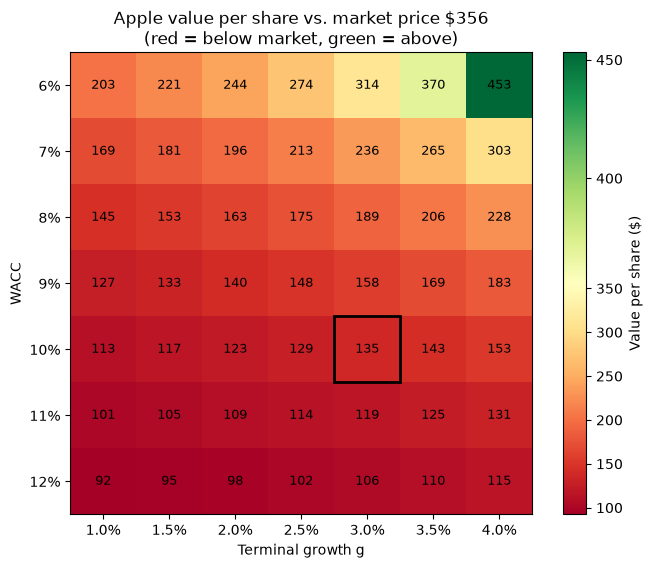

In [139]:
norm = TwoSlopeNorm(vmin=min(table.values.min(), price * 0.9),
                    vcenter=price,
                    vmax=max(table.values.max(), price * 1.1))

fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(table.values, cmap="RdYlGn", norm=norm)

ax.set_xticks(range(len(g_range)))
ax.set_xticklabels(table.columns)
ax.set_yticks(range(len(wacc_range)))
ax.set_yticklabels(table.index)
ax.set_xlabel("Terminal growth g")
ax.set_ylabel("WACC")
ax.set_title(f"Apple value per share vs. market price ${price:.0f}\n(red = below market, green = above)")

for i in range(len(wacc_range)):
    for j in range(len(g_range)):
        ax.text(j, i, f"{table.values[i, j]:.0f}", ha="center", va="center", fontsize=9)

# box around the cell closest to the base case
row = np.argmin(np.abs(wacc_range - wacc))
col = np.argmin(np.abs(g_range - g))
ax.add_patch(Rectangle((col - 0.5, row - 0.5), 1, 1, fill=False, edgecolor="black", linewidth=2))

plt.colorbar(im, label="Value per share ($)")
plt.savefig("sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## Step 8: Reverse DCF
Instead of choosing assumptions and calculating a value, the reverse DCF starts from the market price
and solves for the assumption that justifies it.

### 8a: Manual search for the implied terminal growth rate

In [140]:
def gap_for_g(g_test):
    return dcf_value(fcff_values, wacc, g_test, D, cash, investments, shares) - price

for g_test in [0.03, 0.05, 0.07, 0.08, 0.09]:
    value = dcf_value(fcff_values, wacc, g_test, D, cash, investments, shares)
    print(f"g = {g_test:.0%}: value USD {value:.0f}, gap {gap_for_g(g_test):+.0f}")

g = 3%: value USD 132, gap -223
g = 5%: value USD 171, gap -185
g = 7%: value USD 258, gap -98
g = 8%: value USD 361, gap +5
g = 9%: value USD 640, gap +284


### 8b: Exact solution with a root-finding algorithm
`brentq` (from `scipy.optimize`) searches the interval between 0% and just below the WACC for the
growth rate where the model value equals the market price.

In [141]:
implied_g = brentq(gap_for_g, 0.0, wacc - 0.001)

value_check = dcf_value(fcff_values, wacc, implied_g, D, cash, investments, shares)
print(f"Implied terminal growth: {implied_g:.2%}")
print(f"Check: value at implied g = USD {value_check:.2f} vs. market price USD {price:.2f}")

Implied terminal growth: 7.96%
Check: value at implied g = USD 355.58 vs. market price USD 355.58


### 8c: Implied WACC
The same search, but with terminal growth fixed at 3% and the WACC as the unknown.

In [142]:
def gap_for_wacc(wacc_test):
    return dcf_value(fcff_values, wacc_test, g, D, cash, investments, shares) - price

implied_wacc = brentq(gap_for_wacc, g + 0.001, 0.20)
print(f"Implied WACC (with g = {g:.0%}): {implied_wacc:.2%}")

Implied WACC (with g = 3%): 5.65%


**Interpretation:** At the model's WACC (≈10.2%), the market price implies terminal growth of about 8% per year forever,
roughly twice the long-run nominal growth of the economy (~4%); no company can outgrow the economy indefinitely.
With g fixed at 3%, the market price implies a WACC of about 5.7%, i.e. an equity risk premium of under 1%,
far below the typical 4–6%. Neither assumption is plausible on its own. More likely, the market expects strong growth
for much longer than the 5-year forecast horizon, which a single terminal growth rate cannot capture. A multi-stage
model (e.g. 10 years of high growth before the terminal value) would be a natural extension.

## Step 9: Monte Carlo simulation
Instead of fixed assumptions, the key inputs are drawn at random from probability distributions.
Running the valuation thousands of times gives a distribution of possible values instead of a single number.

### 9a: Drawing random numbers

In [143]:
rng = np.random.default_rng(seed=42)

In [144]:
wacc_draws = rng.normal(loc=wacc, scale=0.01, size=10)
print((wacc_draws * 100).round(2))

[10.48  9.14 10.93 11.12  8.23  8.88 10.31  9.86 10.16  9.32]


Mean:      10.17%
Std. dev.: 1.01%
Share within ±1 sd: 67.8%


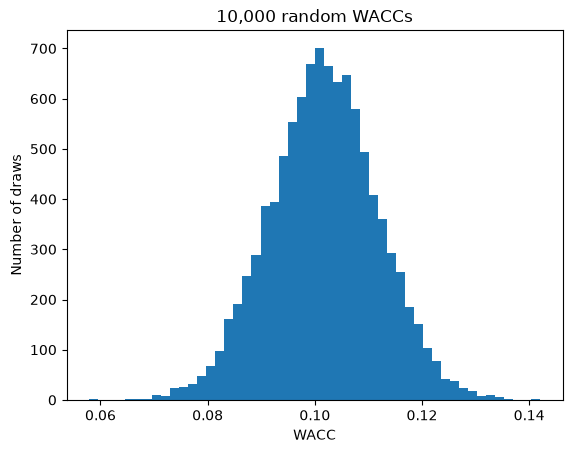

In [145]:
wacc_draws = rng.normal(loc=wacc, scale=0.01, size=10_000)

print(f"Mean:      {wacc_draws.mean():.2%}")
print(f"Std. dev.: {wacc_draws.std():.2%}")
print(f"Share within ±1 sd: {(abs(wacc_draws - wacc) < 0.01).mean():.1%}")

plt.hist(wacc_draws, bins=50)
plt.xlabel("WACC")
plt.ylabel("Number of draws")
plt.title("10,000 random WACCs")
plt.show()

### 9b: Monte Carlo with an uncertain WACC

In [146]:
mc_values = np.array([dcf_value(fcff_values, w, g, D, cash, investments, shares) for w in wacc_draws])

print(f"Simulations: {len(mc_values):,}")
print(f"First 5 values: {mc_values[:5].round(1)}")

Simulations: 10,000
First 5 values: [117.9 119.4 131.  114.5 124.2]


In [147]:
print(f"Base case (fixed WACC): USD {base:.0f}")
print(f"Mean:                   USD {mc_values.mean():.0f}")
print(f"Median:                 USD {np.median(mc_values):.0f}")
print(f"5th percentile:         USD {np.percentile(mc_values, 5):.0f}")
print(f"95th percentile:        USD {np.percentile(mc_values, 95):.0f}")
print(f"Probability value > market price: {(mc_values > price).mean():.1%}")

Base case (fixed WACC): USD 132
Mean:                   USD 135
Median:                 USD 132
5th percentile:         USD 108
95th percentile:        USD 172
Probability value > market price: 0.0%


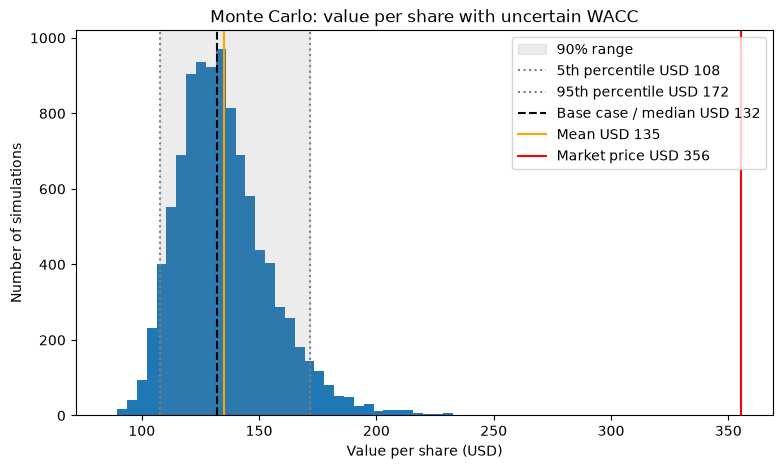

In [148]:
p5 = np.percentile(mc_values, 5)
p95 = np.percentile(mc_values, 95)

plt.figure(figsize=(9, 5))
plt.hist(mc_values, bins=60)

plt.axvspan(p5, p95, color="grey", alpha=0.15, label="90% range")
plt.axvline(p5, color="grey", linestyle=":", label=f"5th percentile USD {p5:.0f}")
plt.axvline(p95, color="grey", linestyle=":", label=f"95th percentile USD {p95:.0f}")
plt.axvline(base, color="black", linestyle="--", label=f"Base case / median USD {base:.0f}")
plt.axvline(mc_values.mean(), color="orange", label=f"Mean USD {mc_values.mean():.0f}")
plt.axvline(price, color="red", label=f"Market price USD {price:.0f}")

plt.xlabel("Value per share (USD)")
plt.ylabel("Number of simulations")
plt.title("Monte Carlo: value per share with uncertain WACC")
plt.legend()
plt.show()

With only the WACC uncertain (normal, mean ≈10.2%, SD 1 percentage point), 90% of simulated values lie between
USD 107 and USD 170. The distribution is right-skewed: because the value reacts more strongly to lower than to
higher WACCs, the mean (USD 134) lies above the median and the base case (both USD 132), an example of
Jensen's inequality. No simulation reaches the market price, so uncertainty about the discount rate alone
cannot explain it.

### 9c: A valuation function that rebuilds the forecast
To make growth uncertain, the forecast itself has to be rebuilt in every simulation.
This function takes the key assumptions, builds the 5-year FCFF forecast, and values it with `dcf_value`.

In [149]:
def value_from_assumptions(growth_path, ebit_margin, wacc, g):
    rev = revenue.iloc[-1]                     # start: last actual revenue (FY2026)
    fcff = []
    for g_year in growth_path:                 # one round per forecast year
        rev = rev * (1 + g_year)
        ebit_f = rev * ebit_margin
        fcff_f = (ebit_f * (1 - tax_rate)
                  + rev * assumptions["da_pct"]
                  + rev * assumptions["capex_pct"]
                  + rev * assumptions["nwc_pct"])
        fcff.append(fcff_f)
    return dcf_value(np.array(fcff), wacc, g, D, cash, investments, shares)

In [150]:
check = value_from_assumptions(assumptions["growth"], assumptions["ebit_margin"], wacc, g)
print(f"New function: USD {check:.2f}")
print(f"Base case:    USD {base:.2f}")

New function: USD 132.18
Base case:    USD 132.18


In [151]:
faster = np.array(assumptions["growth"]) + 0.02
print(f"Growth path +2 points each year: {(faster * 100).round(1)}")
print(f"Value: USD {value_from_assumptions(faster, assumptions['ebit_margin'], wacc, g):.0f}")

Growth path +2 points each year: [10.  9.  7.  6.  5.]
Value: USD 143


Two extra percentage points of growth in each of the five forecast years raise the value by only about USD 11
(to USD 142), less than half the effect of a 1-point lower WACC. Faster growth over five years only shifts the
level of cash flows, while the WACC and terminal growth affect all cash flows forever.

In [152]:
n_sims = 10_000
rng = np.random.default_rng(seed=42)

growth_shift = rng.normal(0, 0.02, n_sims)
margin_draws = rng.normal(assumptions["ebit_margin"], 0.015, n_sims)
wacc_draws = rng.normal(wacc, 0.01, n_sims)
g_draws = rng.normal(0.03, 0.005, n_sims)

g_draws = np.minimum(g_draws, wacc_draws - 0.01)

In [153]:
inputs = pd.DataFrame({
    "Growth shift": growth_shift,
    "EBIT margin": margin_draws,
    "WACC": wacc_draws,
    "Terminal g": g_draws,
})
display((inputs.describe() * 100).round(2))

,Growth shift,EBIT margin,WACC,Terminal g
count,1000000.00,1000000.00,1000000.00,1000000.00
mean,-0.02,32.53,10.19,3.00
std,2.01,1.50,1.00,0.50
min,-8.78,26.67,6.65,0.87
25%,-1.35,31.51,9.52,2.66
50%,-0.03,32.51,10.20,2.99
75%,1.30,33.54,10.86,3.33
max,8.05,38.73,13.86,5.16


In [154]:
base_growth = np.array(assumptions["growth"])
mc_full = np.zeros(n_sims)

for i in range(n_sims):
    mc_full[i] = value_from_assumptions(base_growth + growth_shift[i],
                                        margin_draws[i], wacc_draws[i], g_draws[i])

print(f"Done: {n_sims:,} simulations")

Done: 10,000 simulations


In [155]:
print(f"Base case:        USD {base:.0f}")
print(f"Mean:             USD {mc_full.mean():.0f}")
print(f"Median:           USD {np.median(mc_full):.0f}")
print(f"5th percentile:   USD {np.percentile(mc_full, 5):.0f}")
print(f"95th percentile:  USD {np.percentile(mc_full, 95):.0f}")
print(f"Above market price: {(mc_full > price).sum()} of {n_sims:,} simulations "
      f"({(mc_full > price).mean():.2%})")

Base case:        USD 132
Mean:             USD 136
Median:           USD 132
5th percentile:   USD 101
95th percentile:  USD 182
Above market price: 0 of 10,000 simulations (0.00%)


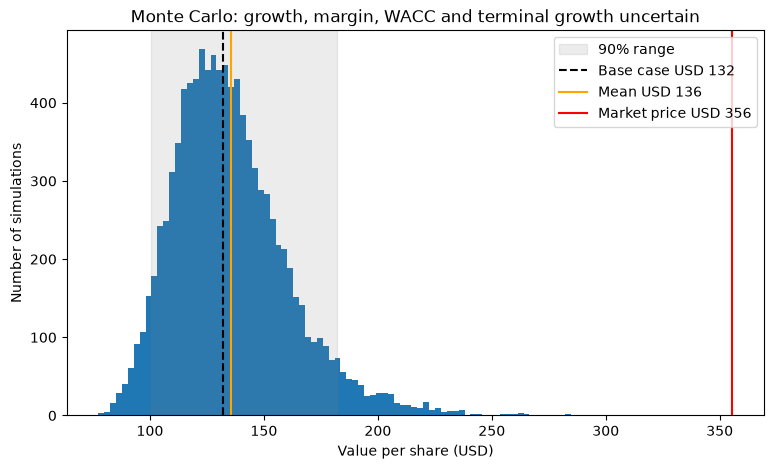

In [157]:
p5, p95 = np.percentile(mc_full, [5, 95])

plt.figure(figsize=(9, 5))
plt.hist(mc_full, bins=80)
plt.axvspan(p5, p95, color="grey", alpha=0.15, label="90% range")
plt.axvline(base, color="black", linestyle="--", label=f"Base case USD {base:.0f}")
plt.axvline(mc_full.mean(), color="orange", label=f"Mean USD {mc_full.mean():.0f}")
plt.axvline(price, color="red", label=f"Market price USD {price:.0f}")
plt.xlabel("Value per share (USD)")
plt.ylabel("Number of simulations")
plt.title("Monte Carlo: growth, margin, WACC and terminal growth uncertain")
plt.legend()
plt.savefig("monte_carlo.png", dpi=150, bbox_inches="tight")
plt.show()

With growth, EBIT margin, WACC and terminal growth all uncertain, 90% of simulated values lie between
USD 101 and USD 182 per share (median USD 132, mean USD 136), wider than with the WACC alone (USD 107–170).
The distribution is right-skewed: the 95th percentile is USD 50 above the median, the 5th only USD 31 below.
None of the 10,000 simulations reaches the market price of about USD 356. Within the range of assumptions
this model treats as plausible, the market price cannot be justified. Combined with the reverse DCF, this
suggests that the market expects strong growth for much longer than the 5-year forecast horizon, a scenario
the model's structure cannot capture. A multi-stage model with a longer high-growth phase would be the
natural extension.

## Conclusion

**Base case.** With a WACC of about 10.2% and 3% terminal growth, the DCF values Apple at about USD 132 per share,
far below the market price of about USD 356 (as of November 2026). The terminal value makes up about 72% of the
enterprise value.

**Sensitivity.** Across WACC 6–12% and terminal growth 1–4%, the value ranges from about USD 92 to USD 453.
The valuation is most sensitive to the WACC, and the effect of terminal growth increases sharply as the WACC falls,
because the terminal value depends on the gap between the two.

**Reverse DCF.** The market price implies either terminal growth of about 8% per year forever (roughly twice
long-run nominal economic growth) or a WACC of about 5.7% (an equity risk premium of under 1%). Neither is
plausible on its own.

**Monte Carlo.** With growth, EBIT margin, WACC and terminal growth all uncertain, 90% of 10,000 simulated values
lie between USD 101 and USD 182 (median USD 132, mean USD 136). The distribution is right-skewed, and none of
the simulations reaches the market price.

**Interpretation.** Within the range of assumptions this model treats as plausible, the market price cannot be
justified. The most likely explanation is that the market expects strong growth for much longer than the 5-year
forecast horizon, a scenario the model's structure cannot capture.

**Limitations and extensions.** The forecast covers only five years, the input distributions in the Monte Carlo
are judgment-based, and Yahoo Finance data is unofficial and changes as it is re-downloaded. A multi-stage model
with a longer high-growth phase would be the natural next step.

**Key takeaway:** a DCF does not reveal a single "true" value; it shows what one has to believe to justify a price.
At Apple's current price, the market is betting on growth that lasts far longer than a standard 5-year forecast assumes.